# Results: tennis match prediction

Reads the files written by `python -m tennis.evaluate` and `python -m tennis.ablation`
(`results/` and `reports/figures/`), so it does not retrain anything. Run those first:

```
python -m tennis.evaluate                          # 2019 (main result)
python -m tennis.evaluate --test-years 2023 2024   # robustness
python -m tennis.ablation
python -m tennis.ablation --test-years 2023 2024
```

All accuracies are **per match** (the two mirrored rows are merged with `combine()`).
A 95% interval is shown as the binomial standard error of the accuracy; differences smaller
than that interval are noise.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES, FIG = ROOT / "results", ROOT / "reports" / "figures"

TAGS = {"2019": "2019 (main result)", "2023-2024": "2023-24 (robustness)"}
MODELS = ["rank_baseline", "logreg", "rf", "linear_svc", "hgb"]
LABEL = {"rank_baseline": "Rank baseline", "logreg": "Logistic regression", "rf": "Random forest",
         "linear_svc": "LinearSVC (calibrated)", "hgb": "HistGradientBoosting"}
COLOR = {"rank_baseline": "#999999", "logreg": "#1f77b4", "rf": "#2ca02c",
         "linear_svc": "#ff7f0e", "hgb": "#d62728"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def load(name):
    p = RES / name
    if not p.exists():
        print(f"(missing {p.relative_to(ROOT)} - run the command listed above)")
        return None
    return pd.read_csv(p)

def ci95(acc, n):
    return 1.96 * np.sqrt(acc * (1 - acc) / n)

metrics = {t: load(f"metrics_{t}.csv") for t in TAGS}
avail = [t for t in TAGS if metrics[t] is not None]

## 1. Model comparison vs the rank baseline

In [2]:
def comparison(tag):
    d = metrics[tag].set_index("model")
    d = d.reindex([m for m in MODELS if m in d.index])
    base = d.loc["rank_baseline", "test_accuracy"]
    return pd.DataFrame({
        "Model": [LABEL[m] for m in d.index],
        "Test acc %": (d.test_accuracy * 100).round(2).values,
        "+/- 95% CI": (ci95(d.test_accuracy, d.n_test_matches) * 100).round(2).values,
        "vs baseline (pts)": ((d.test_accuracy - base) * 100).round(2).values,
        "Train acc %": (d.train_accuracy * 100).round(2).values,
        "Log-loss": d.test_log_loss.round(4).values,
        "Brier": d.test_brier.round(4).values}).reset_index(drop=True)

for t in avail:
    n = int(metrics[t].n_test_matches.iloc[0])
    print(f"Test {TAGS[t]}: {n:,} matches")
    display(comparison(t))

Test 2019 (main result): 2,597 matches


,Model,Test acc %,+/- 95% CI,vs baseline (pts),Train acc %,Log-loss,Brier
0,Rank baseline,61.30,1.87,0.00,65.04,NaN,0.3870
1,Logistic regression,65.65,1.83,4.35,67.77,0.6126,0.2128
2,Random forest,65.96,1.82,4.66,85.11,0.6118,0.2127
3,LinearSVC (calibrated),66.19,1.82,4.89,67.78,0.6116,0.2124
4,HistGradientBoosting,66.08,1.82,4.77,68.42,0.6098,0.2118


Test 2023-24 (robustness): 5,464 matches


,Model,Test acc %,+/- 95% CI,vs baseline (pts),Train acc %,Log-loss,Brier
0,Rank baseline,63.45,1.28,0.00,64.28,NaN,0.3655
1,Logistic regression,66.01,1.26,2.56,67.11,0.6046,0.2097
2,Random forest,65.26,1.26,1.81,85.52,0.6058,0.2100
3,LinearSVC (calibrated),66.07,1.26,2.62,67.09,0.6040,0.2095
4,HistGradientBoosting,66.05,1.26,2.60,67.69,0.6044,0.2097


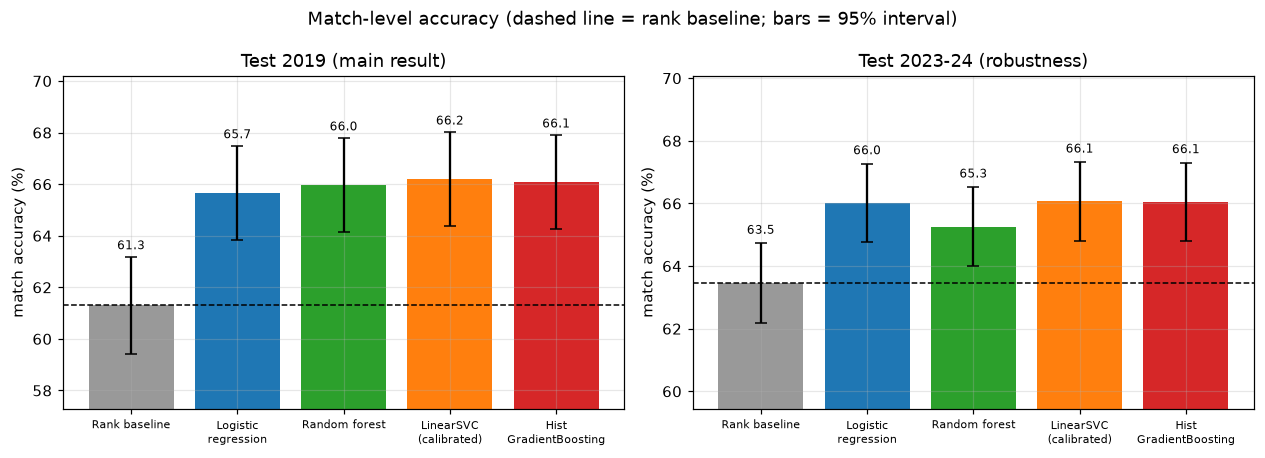

In [3]:
fig, axes = plt.subplots(1, len(avail), figsize=(5.8 * len(avail), 4.2), squeeze=False)
for ax, t in zip(axes[0], avail):
    d = metrics[t].set_index("model").reindex([m for m in MODELS if m in set(metrics[t].model)])
    acc, ci = d.test_accuracy * 100, ci95(d.test_accuracy, d.n_test_matches) * 100
    ax.bar([LABEL[m].replace(" (", "\n(").replace("Gradient", "\nGradient").replace("Logistic ", "Logistic\n")
            for m in d.index], acc, yerr=ci, capsize=4, color=[COLOR[m] for m in d.index])
    ax.axhline(acc["rank_baseline"], color="k", ls="--", lw=1)
    ax.set_ylim(acc.min() - 4, acc.max() + 4)
    ax.set_ylabel("match accuracy (%)")
    ax.set_title(f"Test {TAGS[t]}")
    ax.tick_params(axis="x", labelsize=7.5)
    for i, v in enumerate(acc):
        ax.text(i, v + ci.iloc[i] + 0.3, f"{v:.1f}", ha="center", fontsize=8)
fig.suptitle("Match-level accuracy (dashed line = rank baseline; bars = 95% interval)")
fig.tight_layout(); plt.show()

### Train vs test accuracy

A large gap means the model memorises the training years instead of learning something that
transfers to new seasons.

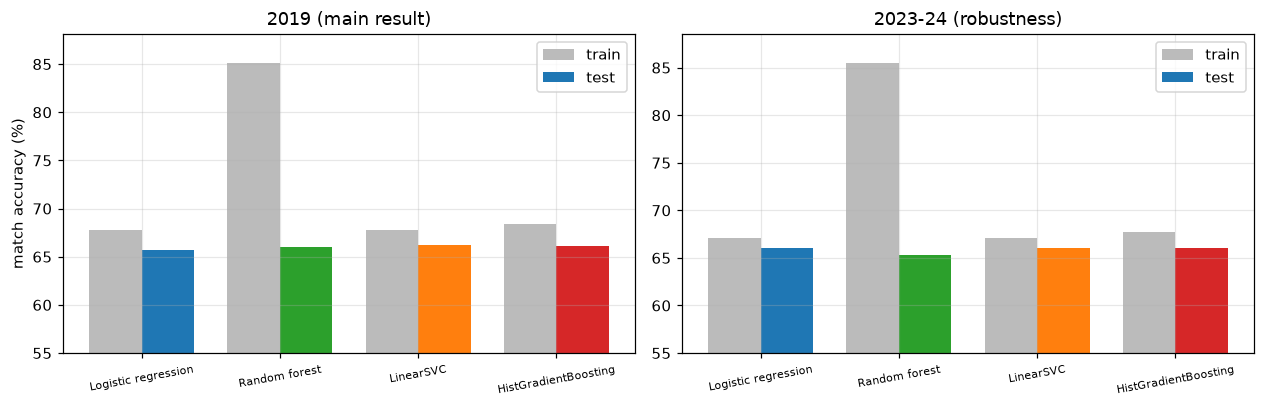

In [4]:
fig, axes = plt.subplots(1, len(avail), figsize=(5.8 * len(avail), 3.8), squeeze=False)
for ax, t in zip(axes[0], avail):
    d = metrics[t].set_index("model").reindex([m for m in MODELS[1:] if m in set(metrics[t].model)])
    x = np.arange(len(d)); w = 0.38
    ax.bar(x - w / 2, d.train_accuracy * 100, w, label="train", color="#bbbbbb")
    ax.bar(x + w / 2, d.test_accuracy * 100, w, label="test", color=[COLOR[m] for m in d.index])
    ax.set_xticks(x); ax.set_xticklabels([LABEL[m].split(" (")[0] for m in d.index], fontsize=7.5, rotation=10)
    ax.set_ylim(55, max(d.train_accuracy.max() * 100 + 3, 70)); ax.set_title(TAGS[t]); ax.legend()
axes[0][0].set_ylabel("match accuracy (%)")
fig.tight_layout(); plt.show()

## 2. Probability quality: log-loss, Brier, calibration

Accuracy only checks which side of 50% the probability falls on. Log-loss and Brier score also
reward *how confident and how right* the probability is (lower is better). The rank baseline
outputs hard 0/1 predictions, so it has no log-loss.

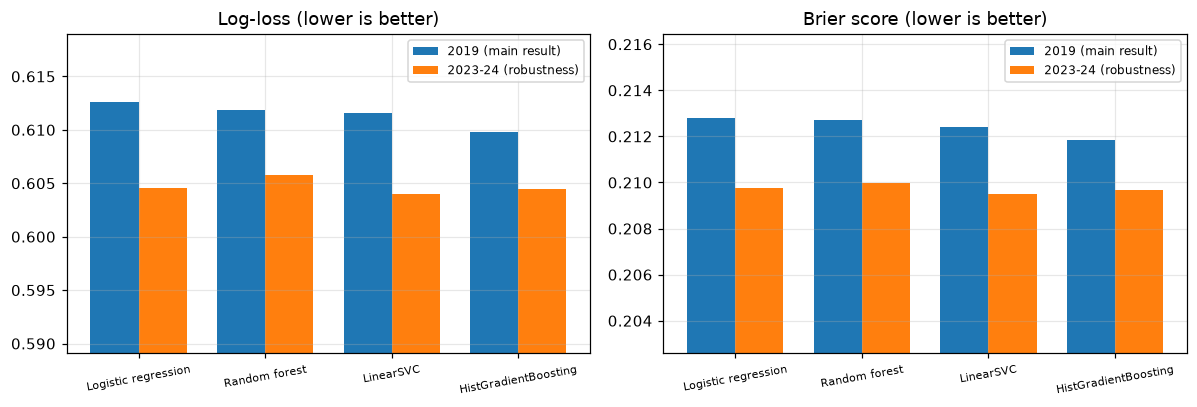

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in ((axes[0], "test_log_loss", "Log-loss (lower is better)"),
                       (axes[1], "test_brier", "Brier score (lower is better)")):
    w = 0.38
    for k, t in enumerate(avail):
        d = metrics[t].set_index("model").reindex([m for m in MODELS[1:] if m in set(metrics[t].model)])
        x = np.arange(len(d))
        ax.bar(x + (k - (len(avail) - 1) / 2) * w, d[col], w, label=TAGS[t])
    ax.set_xticks(np.arange(len(d))); ax.set_xticklabels([LABEL[m].split(" (")[0] for m in d.index],
                                                         fontsize=7.5, rotation=10)
    lo = min(metrics[t][metrics[t].model != "rank_baseline"][col].min() for t in avail)
    hi = max(metrics[t][metrics[t].model != "rank_baseline"][col].max() for t in avail)
    ax.set_ylim(lo - (hi - lo) * 1.5 - 0.002, hi + (hi - lo) * 0.5 + 0.002)
    ax.set_title(title); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**Calibration plots** (each match is used from both players' sides, so the curve is symmetric
around 0.5). A model is well calibrated when the points lie on the diagonal: when it says 70%,
that player should win about 70% of the time.

2019 (main result)


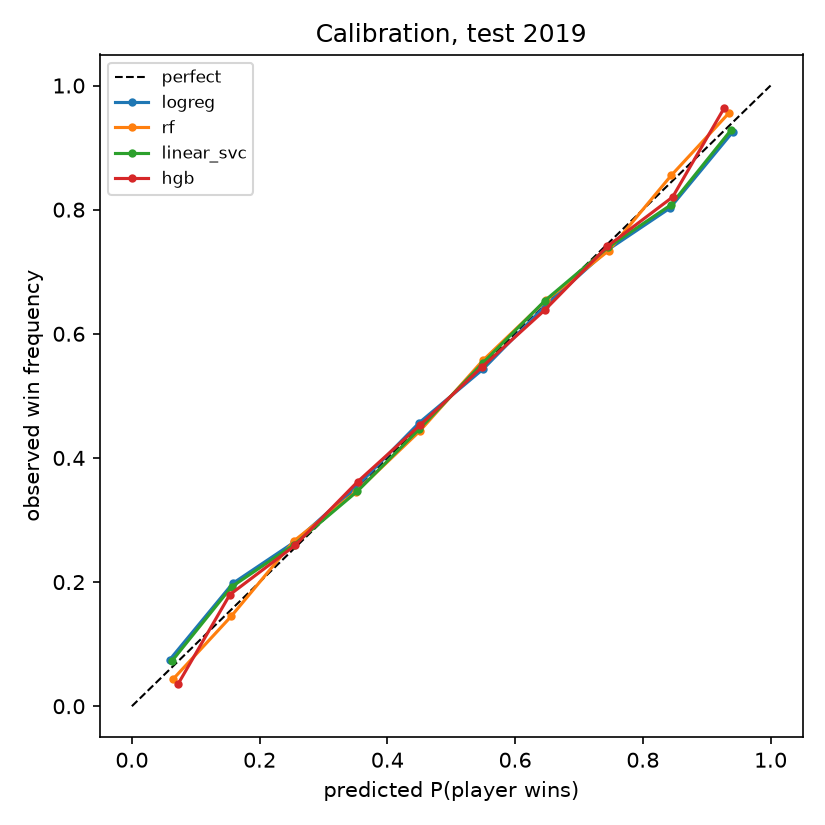

2023-24 (robustness)


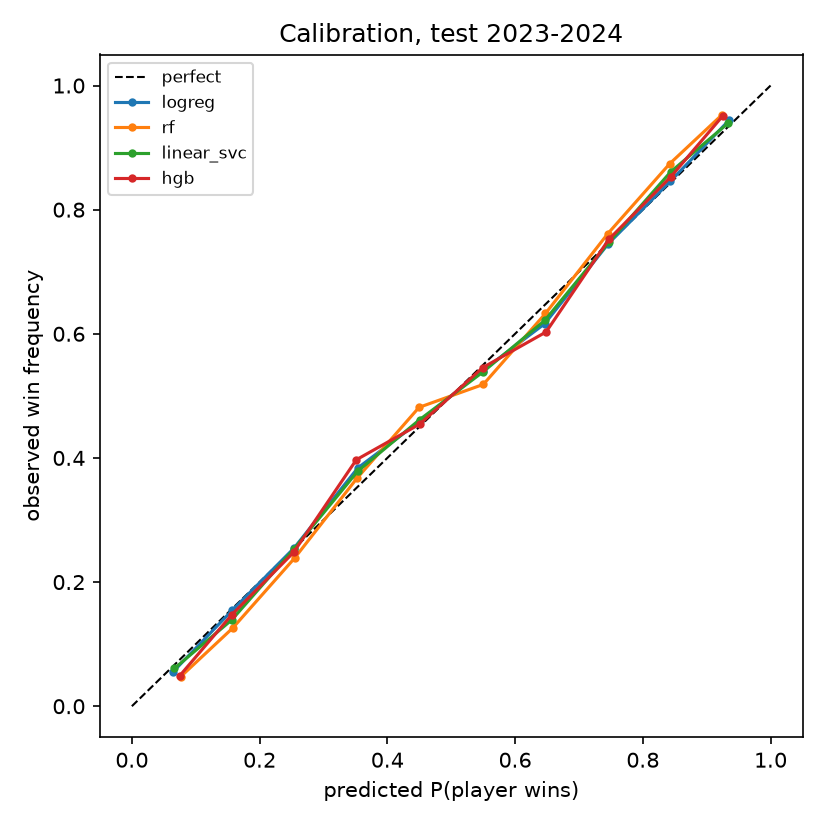

In [6]:
for t in avail:
    p = FIG / f"calibration_{t}.png"
    if p.exists():
        print(TAGS[t]); display(Image(filename=str(p), width=420))
    else:
        print(f"(missing {p.relative_to(ROOT)})")

## 3. Where the model wins and loses: accuracy by rank gap

Matches between players far apart in the rankings are easy, so the rank baseline is strong
there. The interesting part is close matches. `upset_rate` is how often the *worse-ranked*
player won, i.e. how often the baseline is wrong.

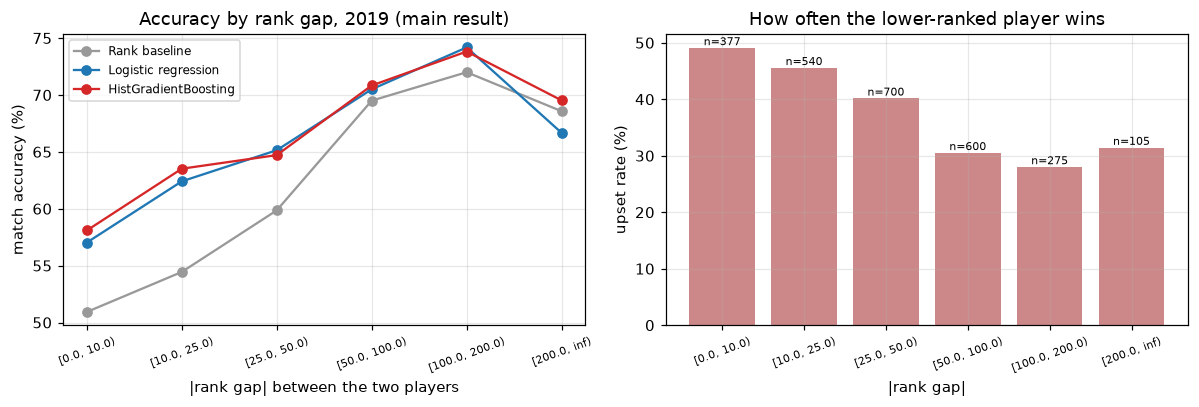

,rank_gap,n,accuracy,upset_rate
0,"[0.0, 10.0)",377,57.0,49.1
1,"[10.0, 25.0)",540,62.4,45.6
2,"[25.0, 50.0)",700,65.1,40.1
3,"[50.0, 100.0)",600,70.5,30.5
4,"[100.0, 200.0)",275,74.2,28.0
5,"[200.0, inf)",105,66.7,31.4


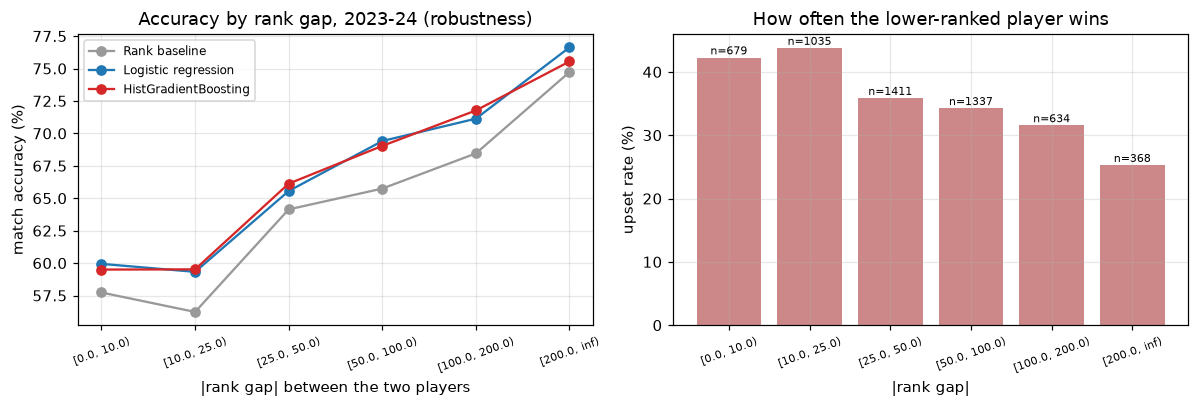

,rank_gap,n,accuracy,upset_rate
0,"[0.0, 10.0)",679,59.9,42.3
1,"[10.0, 25.0)",1035,59.3,43.8
2,"[25.0, 50.0)",1411,65.6,35.9
3,"[50.0, 100.0)",1337,69.4,34.3
4,"[100.0, 200.0)",634,71.1,31.5
5,"[200.0, inf)",368,76.6,25.3


In [7]:
SHOW = ["rank_baseline", "logreg", "hgb"]
for t in avail:
    gaps = {m: load(f"rank_gap_{m}_{t}.csv") for m in SHOW}
    if any(g is None for g in gaps.values()):
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for m in SHOW:
        g = gaps[m]
        axes[0].plot(g["rank_gap"], g["accuracy"] * 100, marker="o", label=LABEL[m], color=COLOR[m])
    axes[0].set_xlabel("|rank gap| between the two players"); axes[0].set_ylabel("match accuracy (%)")
    axes[0].set_title(f"Accuracy by rank gap, {TAGS[t]}"); axes[0].legend(fontsize=8)
    axes[0].tick_params(axis="x", labelsize=7.5, rotation=20)
    g = gaps["logreg"]
    bars = axes[1].bar(g["rank_gap"], g["upset_rate"] * 100, color="#cc8888")
    for b, n in zip(bars, g["n"]):
        axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"n={n}", ha="center", fontsize=7)
    axes[1].set_xlabel("|rank gap|"); axes[1].set_ylabel("upset rate (%)")
    axes[1].set_title("How often the lower-ranked player wins"); axes[1].tick_params(axis="x", labelsize=7.5, rotation=20)
    fig.tight_layout(); plt.show()
    display(gaps["logreg"].assign(accuracy=lambda d: (d.accuracy * 100).round(1),
                                   upset_rate=lambda d: (d.upset_rate * 100).round(1)))

## 4. Feature-group ablation (logistic regression)

* **drop**: all features except one group.  **only**: that group alone.
* **add**: groups added one at a time (rank/attributes, form, surface form, tournament,
  head-to-head, common opponents, serve stats, Elo).
* Error bars are 95% intervals; with a few thousand test matches a difference under about 1.5 to
  2 points is noise, so log-loss (less noisy) is shown as well.

(missing results\ablation_logreg_2023-2024.csv - run the command listed above)


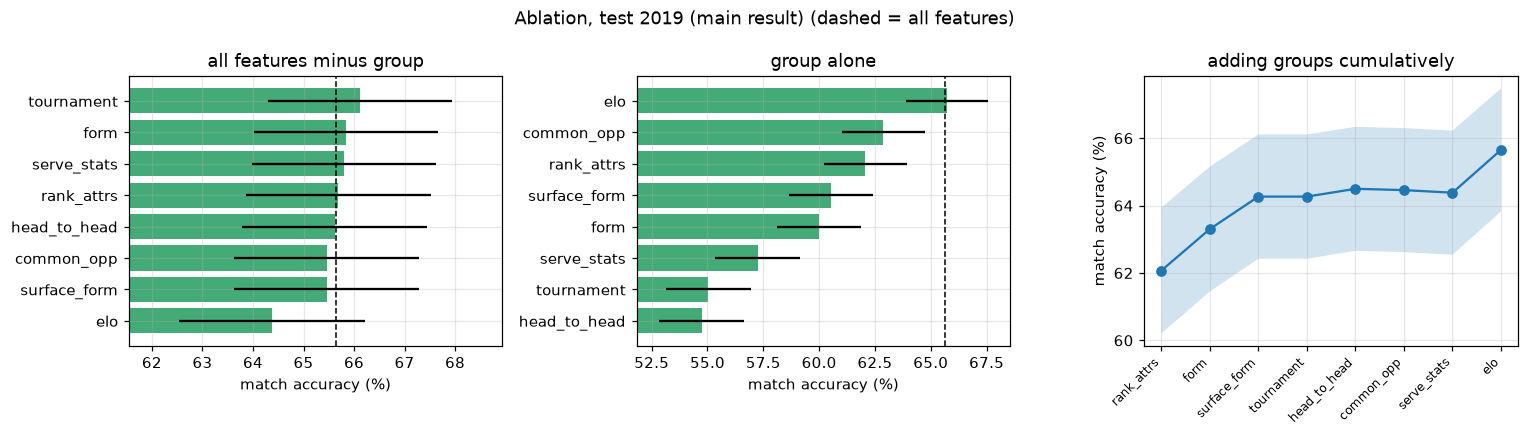

Effect of DROPPING each group (negative acc_vs_all / positive logloss_vs_all = the group helped):


,dropped group,accuracy,acc change (pts),log_loss,logloss_vs_all
0,elo,64.38,-1.27,0.6274,0.0147
1,surface_form,65.46,-0.19,0.6135,0.0008
2,head_to_head,65.61,-0.04,0.6131,0.0005
3,common_opp,65.46,-0.19,0.6127,0.0001
4,serve_stats,65.81,0.15,0.6123,-0.0003
5,tournament,66.11,0.46,0.6123,-0.0004
6,form,65.85,0.19,0.6135,0.0009
7,rank_attrs,65.69,0.04,0.6110,-0.0017


In [8]:
abl = {t: load(f"ablation_logreg_{t}.csv") for t in TAGS}
for t in TAGS:
    a = abl[t]
    if a is None:
        continue
    full = a[a.kind == "all"].iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, kind, title in ((axes[0], "drop", "all features minus group"), (axes[1], "only", "group alone")):
        d = a[a.kind == kind].sort_values("accuracy")
        ax.barh(d.group, d.accuracy * 100, xerr=d.acc_ci95 * 100, color="#4a7")
        ax.axvline(full.accuracy * 100, color="k", ls="--", lw=1)
        ax.set_xlim((d.accuracy - d.acc_ci95).min() * 100 - 1, (d.accuracy + d.acc_ci95).max() * 100 + 1)
        ax.set_title(title); ax.set_xlabel("match accuracy (%)")
    d = a[a.kind == "add"]
    axes[2].plot(range(len(d)), d.accuracy * 100, marker="o")
    axes[2].fill_between(range(len(d)), (d.accuracy - d.acc_ci95) * 100, (d.accuracy + d.acc_ci95) * 100, alpha=0.2)
    axes[2].set_xticks(range(len(d))); axes[2].set_xticklabels(d.group, rotation=45, ha="right", fontsize=8)
    axes[2].set_title("adding groups cumulatively"); axes[2].set_ylabel("match accuracy (%)")
    fig.suptitle(f"Ablation, test {TAGS[t]} (dashed = all features)")
    fig.tight_layout(); plt.show()
    tbl = a[a.kind == "drop"][["group", "accuracy", "acc_vs_all", "log_loss", "logloss_vs_all"]].copy()
    tbl["accuracy"] = (tbl.accuracy * 100).round(2); tbl["acc_vs_all"] = (tbl.acc_vs_all * 100).round(2)
    tbl["log_loss"] = tbl.log_loss.round(4); tbl["logloss_vs_all"] = tbl.logloss_vs_all.round(4)
    print("Effect of DROPPING each group (negative acc_vs_all / positive logloss_vs_all = the group helped):")
    display(tbl.rename(columns={"group": "dropped group", "acc_vs_all": "acc change (pts)"}).reset_index(drop=True))

## 5. What the models learned
Logistic regression coefficients are per standard deviation of the (standardized) feature, so
they are comparable in size. Positive = pushes toward player A winning.

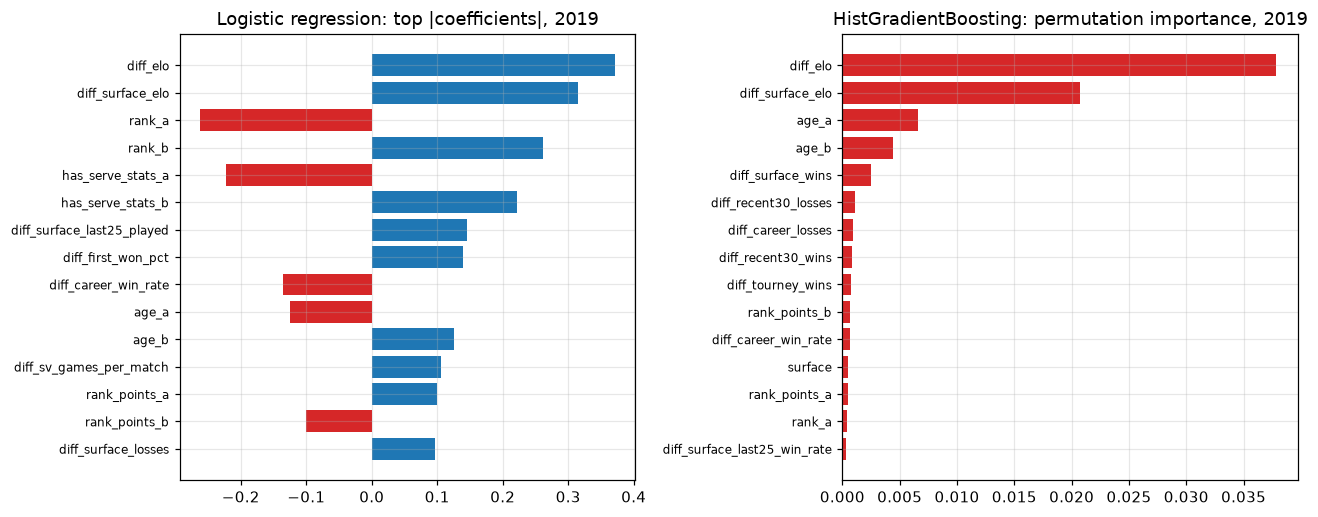

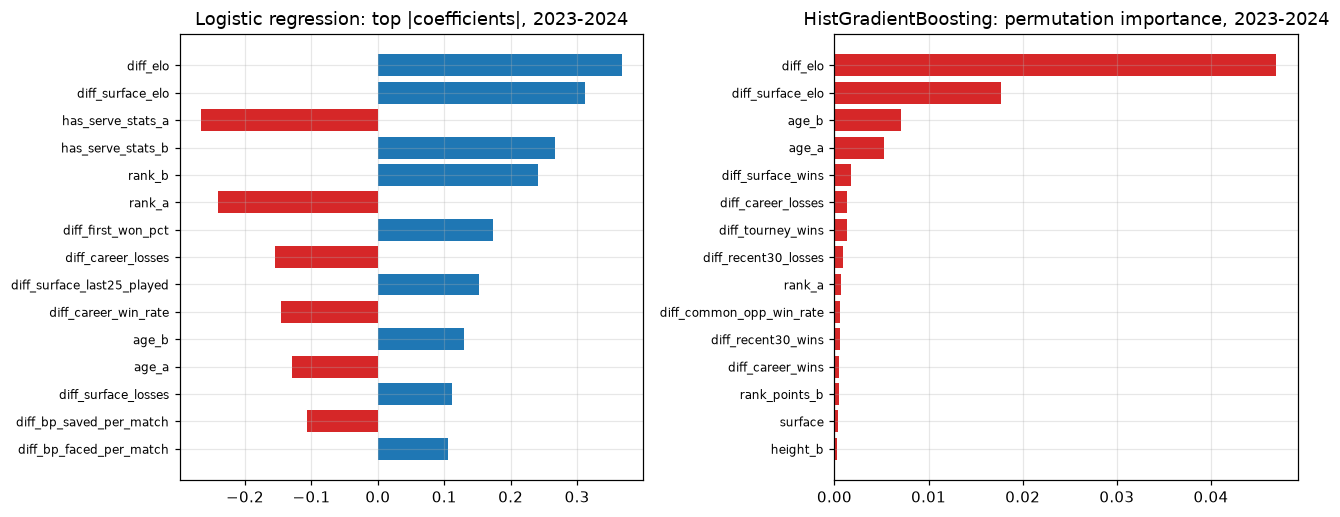

In [9]:
for t in avail:
    e = load(f"explain_logreg_{t}.csv")
    h = load(f"explain_hgb_{t}.csv")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    if e is not None:
        d = e.reindex(e.coef_per_std.abs().sort_values(ascending=False).index).head(15).iloc[::-1]
        axes[0].barh(d.feature, d.coef_per_std, color=["#1f77b4" if v > 0 else "#d62728" for v in d.coef_per_std])
        axes[0].set_title(f"Logistic regression: top |coefficients|, {t}")
    if h is not None:
        d = h.sort_values("importance", ascending=False).head(15).iloc[::-1]
        axes[1].barh(d.feature, d.importance, color="#d62728")
        axes[1].set_title(f"HistGradientBoosting: permutation importance, {t}")
    for ax in axes: ax.tick_params(axis="y", labelsize=8)
    fig.tight_layout(); plt.show()

## 6. Worst misses
Matches where the logistic regression was most confident in the *wrong* player
(`p_win` is the probability it gave to the player who actually won; lower = worse miss).

In [10]:
w = load("worst_misses_logreg_2019.csv")
if w is not None:
    keep = [c for c in ["match_date", "tournament", "round", "surface", "player_a_name", "player_b_name",
                        "player_a", "player_b", "rank_a", "rank_b", "p_win"] if c in w.columns]
    display(w[keep].head(10).round(3))
    print("In these rows player A is the actual winner.")

,match_date,round,surface,player_a_name,player_b_name,rank_a,rank_b,p_win
0,2019-08-26,QF,Hard,Grigor Dimitrov,Roger Federer,78,3,0.038
1,2019-04-15,SF,Clay,Fabio Fognini,Rafael Nadal,18,2,0.046
2,2019-08-26,R16,Hard,Stan Wawrinka,Novak Djokovic,24,1,0.051
3,2019-01-14,R16,Hard,Stefanos Tsitsipas,Roger Federer,15,3,0.057
4,2019-03-04,R32,Hard,Philipp Kohlschreiber,Novak Djokovic,39,1,0.058
5,2019-08-26,R128,Hard,Jenson Brooksby,Tomas Berdych,394,98,0.062
6,2019-07-22,R32,Hard,Kevin King,Grigor Dimitrov,405,53,0.085
7,2019-04-15,QF,Clay,Daniil Medvedev,Novak Djokovic,14,1,0.091
8,2019-01-07,R32,Hard,Jose Rubin Statham,Hyeon Chung,360,25,0.099
9,2018-12-31,SF,Hard,Roberto Bautista Agut,Novak Djokovic,24,1,0.100


In these rows player A is the actual winner.


## 7. Key numbers (computed from the files above)

In [11]:
for t in avail:
    d = metrics[t]
    base = d[d.model == "rank_baseline"].iloc[0]
    m = d[d.model != "rank_baseline"].copy()
    m["ci"] = ci95(m.test_accuracy, m.n_test_matches)
    best = m.sort_values("test_log_loss").iloc[0]
    spread = (m.test_accuracy.max() - m.test_accuracy.min()) * 100
    print(f"[{t}] baseline {base.test_accuracy:.1%}; best by log-loss: {LABEL[best.model]} "
          f"{best.test_accuracy:.1%} (+{(best.test_accuracy - base.test_accuracy) * 100:.1f} pts, "
          f"95% interval +/-{best.ci * 100:.1f}).")
    print(f"       all four models lie within {spread:.1f} pts of each other "
          f"({'inside' if spread < best.ci * 100 else 'outside'} one interval).")
    big = m.loc[(m.train_accuracy - m.test_accuracy).idxmax()]
    print(f"       biggest train/test gap: {LABEL[big.model]} "
          f"({big.train_accuracy:.1%} train vs {big.test_accuracy:.1%} test).")

[2019] baseline 61.3%; best by log-loss: HistGradientBoosting 66.1% (+4.8 pts, 95% interval +/-1.8).
       all four models lie within 0.5 pts of each other (inside one interval).
       biggest train/test gap: Random forest (85.1% train vs 66.0% test).
[2023-2024] baseline 63.5%; best by log-loss: LinearSVC (calibrated) 66.1% (+2.6 pts, 95% interval +/-1.3).
       all four models lie within 0.8 pts of each other (inside one interval).
       biggest train/test gap: Random forest (85.5% train vs 65.3% test).


### Notes for the write-up
* Report the interval with every accuracy; say which differences are **not** significant.
* Elo-only vs all features, and the drop-Elo row of the ablation, answer "why is Elo nearly as good as everything".
* The paper's logistic regression reports 71% with a 65.5% baseline; compare the *margin over the
  baseline* (not the raw number), and mention that its features were chosen using test accuracy.